# CEVA, step by step

How CEVA turns satellite images into shoreline positions, rates of change and their uncertainty, shown on one
beach: **Truc Vert** (Gironde, France), 237 transects over 24 km, 1984–2025.

Each step calls the functions of the production pipeline (`ceva process`, `ceva batch run`) in the order the
pipeline does, and shows what they produce. Step 13 checks that the result is the pipeline's, to the last
digit; step 14 compares it with field surveys; step 15 computes the coastal vulnerability index.

**Before running it** (see the README): the CEVA environment, a data directory (`CEVA_DATA_DIR` in `.env`), the
transects (`ceva transects prepare --continent Europe`), the EOT20 tide files, the ERA5 waves
(`ceva waves download` and `ceva waves build`), the images of the beach (`ceva process truc_vert`, a few
minutes, no account needed), for step 14 the surveys (`ceva validate --download`) and, for step 15, the
sources of the vulnerability index (`ceva vulnerability prepare`).

## 1. Setup

The configuration is the packaged defaults plus the region file (`config/regions/truc_vert.yaml`). The values used below come from it.

In [1]:
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import LineString

from ceva import engines, pipeline, products, shoreline, waves
from ceva.change_metrics import classify_lrr
from ceva.config import load_config
from ceva.credentials import load_local_settings
from ceva.cube import open_cube
from ceva.tides import TideTable

load_local_settings()                       # CEVA_DATA_DIR from .env
warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False,
                     "axes.spines.right": False})
LANDSAT, SENTINEL2 = "#2a78d6", "#eb6834"   # the two sensor families in every figure

REGION = "truc_vert"
cfg = load_config(REGION)
pd.Series({
    "detection method": cfg.perimage.engine,
    "sample spacing along a transect (m)": cfg.cube.spacing_m,
    "search window around the expected waterline (m)": cfg.perimage.max_dist_ref_m,
    "tide band of the yearly composites (share of the range)": cfg.annual.tide_central_fraction,
    "tide model": cfg.tides.model,
    "wave correction (m per m of wave height above usual)": cfg.waves.empirical.hs_coef[cfg.perimage.engine],
    "beach slope method": cfg.perimage.slope_method,
    "reference elevation (m above mean sea level)": cfg.tides.reference_elevation_m,
}, name="value").to_frame()

,value
detection method,ceva
sample spacing along a transect (m),10.0
search window around the expected waterline (m),150.0
tide band of the yearly composites (share of the range),0.5
tide model,EOT20
wave correction (m per m of wave height above usual),0.48
beach slope method,spectral
reference elevation (m above mean sea level),0.0


## 2. Transects

Positions are measured along the transects of the Global Coastal Transect System (GCTS): lines 2 km long,
100 m apart, across the coast, with the same identifiers everywhere on Earth. A shoreline position is a
distance in metres along a transect, from its landward end.

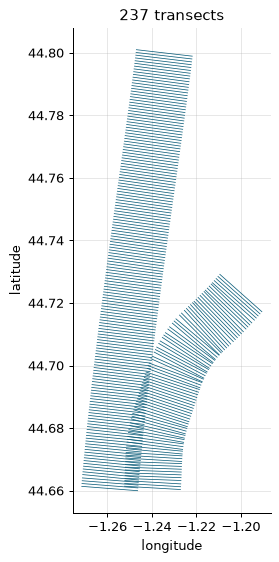

In [2]:
ds = open_cube(cfg, REGION).load()
ids = ds["transect_id"].values.astype(str)
lon0, lat0, lon1, lat1 = (ds[v].values for v in ("lon_start", "lat_start", "lon_end", "lat_end"))
fig, ax = plt.subplots(figsize=(4, 7))
ax.plot(np.stack([lon0, lon1]), np.stack([lat0, lat1]), color="#0b5d7a", lw=0.6)
ax.set(title=f"{len(ids)} transects", xlabel="longitude", ylabel="latitude", aspect=1 / np.cos(np.radians(44.7)))
plt.show()

## 3. The images, read along the transects

Every clear-enough Landsat 4–9 (30 m) and Sentinel-2 (10 m) image, as surface reflectance from the Planetary
Computer, is read **on its own grid** at points every 10 m along each transect: the green and short-wave
infrared bands, and the image's quality flags. Nothing is resampled onto a common raster. Scenes of one
satellite on one day form one acquisition. The result is the *cube* (time, transect, distance), stored once
and versioned, so every later step can change without reading the images again.

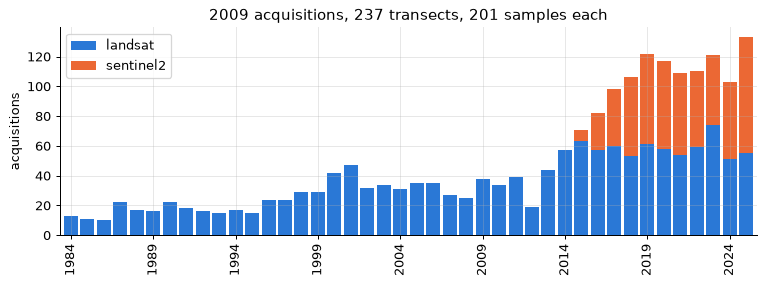

In [3]:
times = pd.DatetimeIndex(ds["time"].values)
family = ds["family"].values.astype(str)
counts = pd.crosstab(times.year, family)
ax = counts.plot.bar(stacked=True, color=[LANDSAT, SENTINEL2], width=0.85, figsize=(10, 3))
ax.set(xlabel="", ylabel="acquisitions",
       title=f"{len(times)} acquisitions, {ds.sizes['transect']} transects, {ds.sizes['distance']} samples each")
ax.legend(title=None)
ax.set_xticks(range(0, len(counts), 5), counts.index[::5])
plt.show()

## 4. Water index and cloud mask

Water absorbs short-wave infrared much more than green light. The **modified normalised difference water
index** (Xu 2006), MNDWI = (green − SWIR) / (green + SWIR), is positive over water and negative over sand.
Samples the quality flags reject are dropped: for Landsat fill, dilated cloud, cirrus, cloud, shadow and
snow; for Sentinel-2 no data, saturated, high-probability cloud and thin cirrus (its shadow and snow classes
often fall on dry sand and white water).

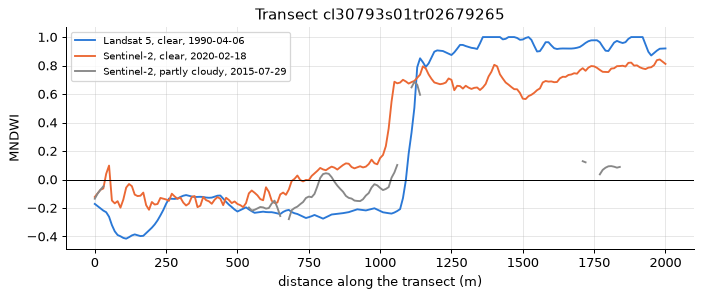

In [4]:
index = shoreline.mndwi(ds["green"].values, ds["swir1"].values)
clear = shoreline.clear_sky(ds["qa"].values, family == "landsat", cfg.masking.landsat_qa_drop_bits,
                            cfg.masking.s2_scl_drop_classes)
distance = ds["distance"].values
demo = list(ids).index("cl30793s01tr02679265")       # a transect near the middle of the beach
clear_share = clear[:, demo, :].mean(axis=1)
def clearest(mask):                                  # the image with the most clear samples among these
    candidates = np.flatnonzero(mask)
    return candidates[np.argmax(clear_share[candidates])]

picks = {"Landsat 5, clear": clearest((family == "landsat") & (times.year == 1990)),
         "Sentinel-2, clear": clearest((family == "sentinel2") & (times.year == 2020)),
         "Sentinel-2, partly cloudy": np.flatnonzero((family == "sentinel2") & (clear_share > 0.3)
                                                     & (clear_share < 0.7))[0]}
fig, ax = plt.subplots(figsize=(9, 3.2))
for (label, t), colour in zip(picks.items(), [LANDSAT, SENTINEL2, "#888"], strict=True):
    ax.plot(distance, np.where(clear[t, demo], index[t, demo], np.nan), color=colour,
            label=f"{label}, {times[t]:%Y-%m-%d}")
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel="distance along the transect (m)", ylabel="MNDWI", title=f"Transect {ids[demo]}")
ax.legend(fontsize=8)
plt.show()

## 5. Tides

The waterline in an image sits wherever the sea was at that moment. The tide height at each transect and
image time comes from the **EOT20** global tide model (Hart-Davis et al. 2021). Satellites pass at about the
same time of day, so they sample the tide unevenly: some tide levels are seen far more often than others.

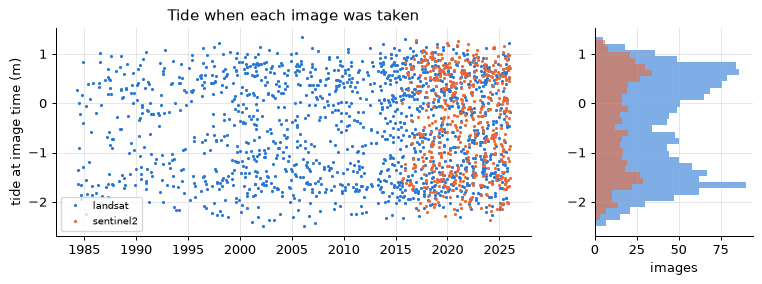

In [5]:
lon_mid, lat_mid = (lon0 + lon1) / 2, (lat0 + lat1) / 2
tides = TideTable(cfg, lon_mid, lat_mid)
tides.prefetch(times)
tide = tides(times)                                   # [time, transect], m above mean sea level
fig, axes = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw={"width_ratios": [3, 1]})
for fam, colour in (("landsat", LANDSAT), ("sentinel2", SENTINEL2)):
    sel = family == fam
    axes[0].plot(times[sel], tide[sel, demo], ".", ms=3, color=colour, label=fam)
    axes[1].hist(tide[sel, demo], bins=30, color=colour, alpha=0.6, orientation="horizontal")
axes[0].set(ylabel="tide at image time (m)", title="Tide when each image was taken")
axes[1].set(xlabel="images")
axes[0].legend(fontsize=8)
plt.show()

## 6. Land side and sea side

`load_profiles` applies the mask of step 4, keeps the tide of step 5, and orients each transect from land to
sea: the long-term median MNDWI must be on the land side of the threshold at one end and on the water side
at the other. Where both ends are land or both are water (a spit, a lagoon, an island narrower than a
transect) the transect cannot be measured and is left out.

In [6]:
profiles = engines.load_profiles(ds, cfg, tide)
pd.Series(profiles.seaward_sign).map({1: "stored land to sea", -1: "flipped", 0: "left out"}).value_counts()

stored land to sea    237
Name: count, dtype: int64

## 7. Yearly composites: a first, robust position

For each year, the images taken near mean sea level (the central half of the tide range) are combined into a
**median MNDWI profile** per transect, as DEA Coastlines does (Bishop-Taylor et al. 2021). The land/water
threshold is set by **Otsu's method** on the samples near a first guess, so it sits between the sand and
water values actually present, and the shoreline is where the profile crosses it, to a fraction of a sample.
These yearly positions guide the detection on single images.

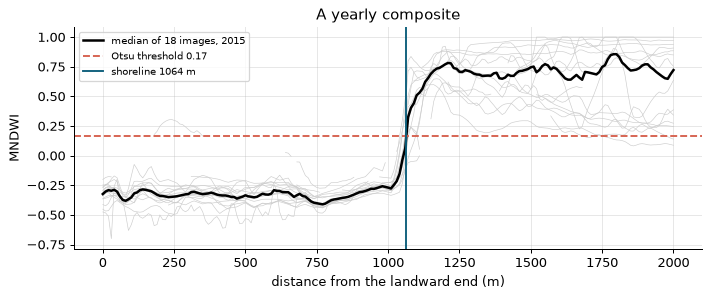

In [7]:
subsets = {"all": None, "landsat": profiles.family == "landsat", "sentinel2": profiles.family == "sentinel2"}
composites = [engines.annual_shorelines(profiles, cfg, subset, label) for label, subset in subsets.items()]
year = 2015
eligible = engines.eligible_for_composite(profiles, cfg)
sel = eligible[:, demo] & (profiles.year == year)
median = np.nanmedian(profiles.index[sel, demo, :], axis=0)
row = composites[0].query("transect_id == @ids[@demo] and year == @year").iloc[0]
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(profiles.distance, profiles.index[sel, demo, :].T, color="#ccc", lw=0.5)
ax.plot(profiles.distance, median, color="k", lw=2, label=f"median of {sel.sum()} images, {year}")
ax.axhline(row["threshold"], color="#d6604d", ls="--", label=f"Otsu threshold {row['threshold']:.2f}")
ax.axvline(row["x"], color="#0b5d7a", label=f"shoreline {row['x']:.0f} m")
ax.set(xlabel="distance from the landward end (m)", ylabel="MNDWI", title="A yearly composite")
ax.legend(fontsize=8)
plt.show()

## 8. Where the waterline sits at each tide

On a flat beach the tide moves the waterline by hundreds of metres, more than a fixed search window around
the yearly position. All the images of a transect are split into eight groups by tide height; each group's
composite gives where the waterline sits at that tide. A rising tide cannot move the waterline seaward, so
the curve is made non-increasing. The search for each image then starts from the year's position, moved
along this curve to the image's tide.

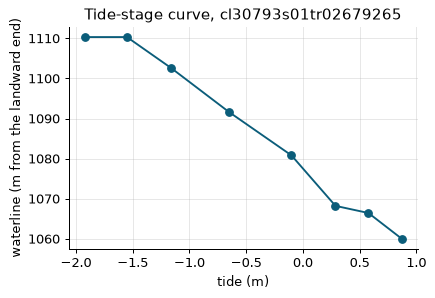

In [8]:
curves = engines.tide_stage_curves(profiles, cfg)
curve = curves[curves["transect_id"] == ids[demo]]
fig, ax = plt.subplots(figsize=(5, 3.2))
ax.plot(curve["tide"], curve["x"], "o-", color="#0b5d7a")
ax.set(xlabel="tide (m)", ylabel="waterline (m from the landward end)", title=f"Tide-stage curve, {ids[demo]}")
plt.show()

## 9. One waterline per image

On each image, the waterline is where the MNDWI profile crosses an Otsu threshold computed on that image,
searched within ±150 m of the expected position of step 8. Profiles with too few clear samples in the window
are rejected. Each waterline keeps the tide of its image.

218,030 waterlines on 237 transects


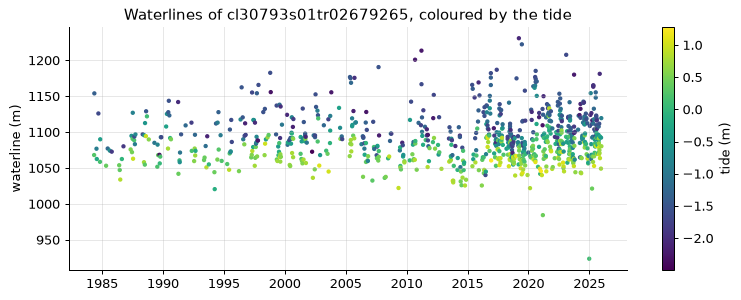

In [9]:
raw = engines.perimage_waterlines(profiles, composites[0], cfg, curves)
one = raw[raw["transect_id"] == ids[demo]]
fig, ax = plt.subplots(figsize=(10, 3.5))
sc = ax.scatter(one["time"], one["x_obs"], c=one["tide"], s=6, cmap="viridis")
fig.colorbar(sc, label="tide (m)")
ax.set(ylabel="waterline (m)", title=f"Waterlines of {ids[demo]}, coloured by the tide")
print(f"{len(raw):,} waterlines on {raw['transect_id'].nunique()} transects")
plt.show()

## 10. Moving every waterline to mean sea level

A waterline seen at water level *z* lies *z* / tan β further landward than the mean-sea-level shoreline, with
tan β the beach slope. The water level is the tide plus the waves' set-up and run-up.

* **Waves** come from ERA5 (Hersbach et al. 2020) at a point 20 km offshore. The waterline sits higher when
  waves are above their usual height: 0.48 m per metre of significant wave height above the transect's mean
  (fitted on six surveyed beaches).
* **Slope**, per transect, by the spectral method of Vos et al. (2020): the slope that removes the tide's
  signal from the corrected series. It is estimated with the tide, then again with tide plus waves.
* **Outliers**: positions more than 3 scaled median absolute deviations from the transect's running median
  are left out of the yearly values.

`pipeline.correct_waterlines` does these steps; they are spelt out here and checked against it.

waves at -1.50, 44.50; median beach slope 0.047; 5.9% of the waterlines are outliers


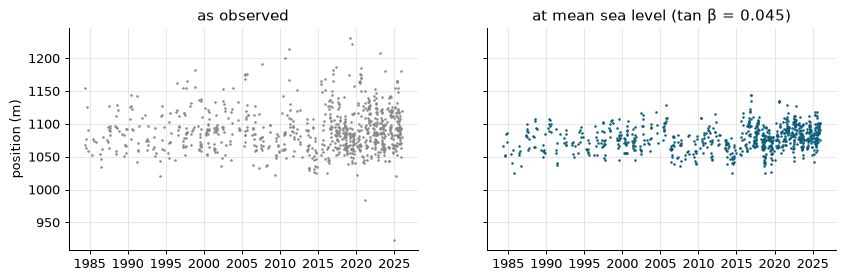

In [10]:
start, end = (times.min() - pd.Timedelta(days=2)).date(), (times.max() + pd.Timedelta(days=2)).date()
sea, point = waves.waves_for_unit(cfg, lon0, lat0, lon1, lat1, profiles.seaward_sign, start, end)

w = raw.copy()
w["wave"], w["level"] = 0.0, w["tide"]
hs = pd.Series(waves.hs_at(sea, w["time"]), index=w.index)
coef = cfg.waves.empirical.hs_coef[cfg.perimage.engine]
w["wave"] = waves.empirical_level(hs, hs.groupby(w["transect_id"]).transform("mean"), coef)
w["level"] = w["tide"] + w["wave"]
est = engines.estimate_slopes(w, cfg.perimage.slope_bounds, level="level", method=cfg.perimage.slope_method)
tan_beta = est.set_index("transect_id")["slope"]
tan_beta = tan_beta.fillna(tan_beta.median())          # transects without an estimate: the beach's median
w["x_corr"] = engines.tide_correct(w, tan_beta, cfg.tides.reference_elevation_m, level="level")
w["outlier"] = engines.flag_outliers(w, "x_corr", cfg.perimage.outlier_mad_k)

waterlines, slopes, unit_slope = pipeline.correct_waterlines(cfg, raw, sea)
assert np.allclose(w["x_corr"], waterlines["x_corr"], equal_nan=True) and (w["outlier"] == waterlines["outlier"]).all()
print(f"waves at {point[0]:.2f}, {point[1]:.2f}; median beach slope {unit_slope:.3f}; "
      f"{waterlines['outlier'].mean():.1%} of the waterlines are outliers")
one = waterlines[waterlines["transect_id"] == ids[demo]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
axes[0].plot(one["time"], one["x_obs"], ".", ms=2, color="#888")
axes[0].set(title="as observed", ylabel="position (m)")
kept = one[~one["outlier"]]
axes[1].plot(kept["time"], kept["x_corr"], ".", ms=2, color="#0b5d7a")
axes[1].set(title=f"at mean sea level (tan β = {tan_beta[ids[demo]]:.3f})")
plt.show()

## 11. Yearly positions and their precision

The yearly shoreline is the **median** of the year's corrected waterlines (at least three). Its standard
error comes from the scatter of single positions around the running median and the number of images that
year, with at most 12 counted as independent a year (images close in time err alike). It measures how
repeatable the position is, not how close it is to the truth (step 14 measures that).

9,894 transect-years; median standard error 3.5 m


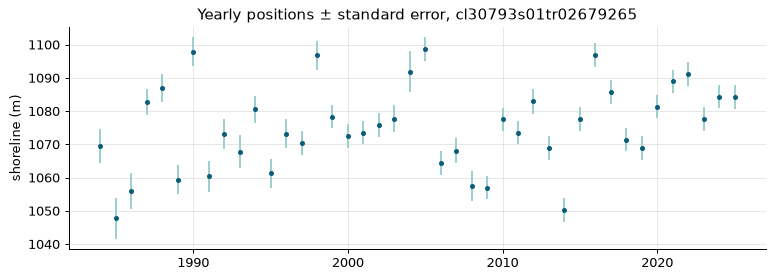

In [11]:
table = pd.DataFrame({"transect_id": ids, "seaward_sign": profiles.seaward_sign, "length": ds["length"].values,
                      "lon": lon_mid, "lat": lat_mid})
lines = gpd.GeoDataFrame(table.merge(slopes, on="transect_id", how="left"), crs=4326,
                         geometry=[LineString([(a, b), (c, d)]) for a, b, c, d in zip(lon0, lat0, lon1, lat1, strict=True)])
yearly = products.yearly_products(cfg, lines, waterlines, None)["imagery"]
mine = yearly[yearly["transect_id"] == ids[demo]]
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.errorbar(mine["year"], mine["x"], yerr=mine["se_m"], fmt="o", ms=3, color="#0b5d7a", ecolor="#9cc")
ax.set(ylabel="shoreline (m)", title=f"Yearly positions ± standard error, {ids[demo]}")
print(f"{len(yearly):,} transect-years; median standard error {yearly['se_m'].median():.1f} m")
plt.show()

## 12. Rate of change, its uncertainty, its class

The **rate** is the slope of an ordinary least-squares line through the yearly positions (m/yr, positive
seaward), with its **95 % interval** (Student's t), given at least five years. A trend is **significant**
when its interval excludes zero. Rates are classed after Luijendijk et al. (2018): stable within ±0.5 m/yr,
then erosion or accretion (0.5–1), intense (1–3), severe (3–5) and extreme (beyond 5).

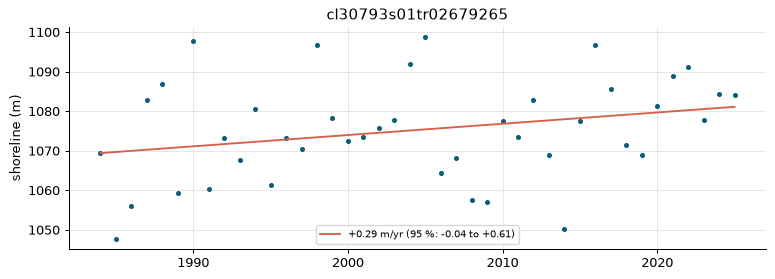

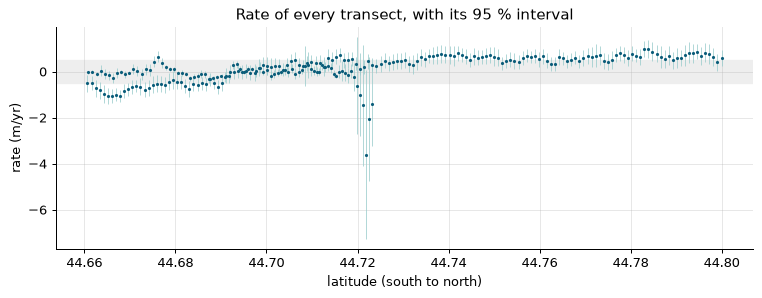

,transects,significant
class,,
stable,135,44%
accretion,70,100%
erosion,25,92%
intense_erosion,6,50%
severe_erosion,1,0%


In [12]:
rates = products.product_rates(yearly)
fit = rates.set_index("transect_id").loc[ids[demo]]
ax = plt.subplots(figsize=(10, 3.2))[1]
ax.plot(mine["year"], mine["x"], "o", ms=3, color="#0b5d7a")
yr = np.array([fit["first_year"], fit["last_year"]])
centre = np.average(mine["year"]), np.average(mine["x"])
ax.plot(yr, centre[1] + fit["rate"] * (yr - centre[0]), color="#d6604d",
        label=f"{fit['rate']:+.2f} m/yr (95 %: {fit['rate_lo']:+.2f} to {fit['rate_hi']:+.2f})")
ax.set(ylabel="shoreline (m)", title=ids[demo])
ax.legend(fontsize=8)
plt.show()

rates["significant"] = (rates["rate_lo"] > 0) | (rates["rate_hi"] < 0)
rates["class"] = rates["rate"].map(classify_lrr)
order = rates.merge(table[["transect_id", "lat"]], on="transect_id").sort_values("lat")
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.axhspan(-0.5, 0.5, color="#eee", label="stable")
ax.errorbar(order["lat"], order["rate"], yerr=[order["rate"] - order["rate_lo"], order["rate_hi"] - order["rate"]],
            fmt=".", ms=3, color="#0b5d7a", ecolor="#9cc", lw=0.6)
ax.set(xlabel="latitude (south to north)", ylabel="rate (m/yr)", title="Rate of every transect, with its 95 % interval")
plt.show()
rates["class"].value_counts().to_frame("transects").join(
    rates.groupby("class")["significant"].mean().rename("significant").map("{:.0%}".format))

## 13. The same result as the pipeline

`pipeline.run` chains steps 3 to 12 for any unit; `ceva process` and `ceva batch run` call it. Run on the same
cube, it gives the same positions and rates.

In [13]:
res = pipeline.run(pipeline.variant_config(cfg, "ceva"), REGION, "ceva")
stored = products.load_products(pipeline.results_dir(cfg, REGION, "ceva"))["imagery"][1]
check = rates.merge(stored, on="transect_id", suffixes=("", "_pipeline"))
print(f"{len(check)} transects; largest difference in rate: "
      f"{np.nanmax(np.abs(check['rate'] - check['rate_pipeline'])):.2e} m/yr")

237 transects; largest difference in rate: 0.00e+00 m/yr


## 14. Accuracy against field surveys

At Truc Vert the beach was surveyed every 2 to 4 weeks from 2003 to 2019 (Castelle et al. 2020). The
validation run (`ceva validate`) processes the survey lines themselves, with the same settings. Each
satellite waterline is compared with the survey interpolated to its date (within 10 days on both sides, else
the nearest within 3 days), and each yearly position with that year's median surveyed position (years with
at least four surveys).

In [14]:
from ceva.validation import trucvert
from ceva.validation.compare import error_metrics, match_in_time

site = pipeline.load(cfg, "trucvert", "ceva")
surveys = trucvert.surveys(cfg)
used = site.waterlines[site.waterlines["use"]]
single = match_in_time(used, surveys, "x_corr")
per_year = surveys.assign(year=surveys["time"].dt.year).groupby(["transect_id", "year"])["x"].agg(["median", "size"])
survey_years = per_year.loc[per_year["size"] >= 4, "median"]
years = site.annual.query("engine == 'perimage' and sensors == 'all'").join(
    survey_years.rename("x_survey"), on=["transect_id", "year"]).dropna(subset=["x_survey"])
years["error"] = years["x"] - years["x_survey"]
pd.DataFrame({"single images": error_metrics(single["error"]),
              "yearly positions": error_metrics(years["error"])}).round(1)

,single images,yearly positions
n,2748.0,213.0
bias,-12.2,-10.7
std,20.2,8.3
rmse,23.6,13.5
mae,17.0,11.6


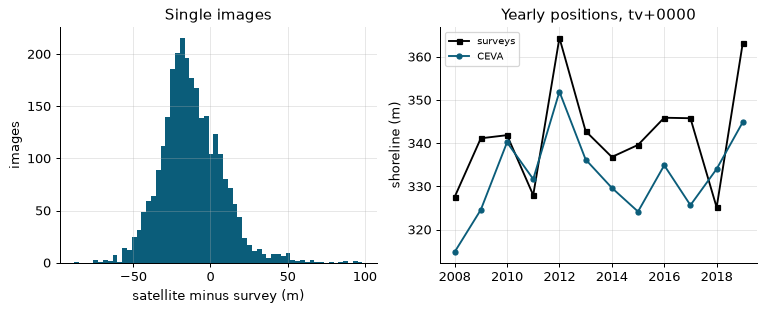

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(single["error"].clip(-100, 100), bins=60, color="#0b5d7a")
axes[0].set(xlabel="satellite minus survey (m)", ylabel="images", title="Single images")
one = years[years["transect_id"] == years["transect_id"].iloc[0]]
axes[1].plot(one["year"], one["x_survey"], "s-", color="k", ms=4, label="surveys")
axes[1].plot(one["year"], one["x"], "o-", color="#0b5d7a", ms=4, label="CEVA")
axes[1].set(ylabel="shoreline (m)", title=f"Yearly positions, {one['transect_id'].iloc[0]}")
axes[1].legend(fontsize=8)
plt.show()

The yearly positions are within about 14 m of the surveys (root mean square), single images within about
24 m; the README gives the six validation beaches.

## 15. Coastal vulnerability index

The index of Thieler and Hammar-Klose (1999, USGS) ranks six variables from 1 (low vulnerability) to 5 (very
high) and combines them as CVI = √(product of the ranks / 6).

| Variable | From | Rank 5 when |
|---|---|---|
| landform | Global Coastal Typology | dunes, sediment plain, wetland |
| shoreline change | the rate of step 12 | retreat of 2 m/yr or more |
| regional slope | GEBCO 2024, a straight line from 5 km offshore to the highest ground within 5 km inland | under 0.3 % |
| relative sea-level rise | sea-surface trend (Copernicus Marine altimetry) minus the land uplift of glacial isostatic adjustment (ICE-6G_C VM5a) | over 3.4 mm/yr |
| mean wave height | ERA5 at the unit's offshore point | over 1.25 m |
| mean tidal range | EOT20, mean daily range over a year | under 1 m |

The slope's fit stops at the crest: lakes and low land behind the dunes would otherwise flatten it.

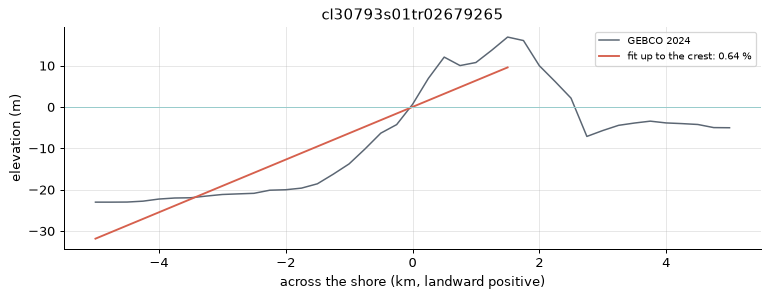

CVI = 23.7


,value,rank
geomorphology,dune,5
shoreline_change,+0.29 m/yr,3
coastal_slope,0.64 %,3
sea_level,"+5.1 mm/yr (sea +4.9, land -0.2)",5
waves,1.77 m,5
tide,2.93 m,3


In [16]:
from ceva import vulnerability
from ceva.transects import typology

coast = vulnerability.unit_transects(cfg, REGION)
coast = coast.merge(typology.load(cfg, coast["transect_id"].tolist())[["transect_id", "coastal_type"]],
                    on="transect_id", how="left")
vi = vulnerability.transect_index(cfg, coast).set_index("transect_id")

one = coast.set_index("transect_id").loc[ids[demo]]
s, z = vulnerability.slope_profiles(cfg, [one["lon"]], [one["lat"]], [one["azimuth"]])
top = vulnerability.crests(s, z)[0]
line = np.polyfit(s[:top + 1], z[0, :top + 1], 1)
ax = plt.subplots(figsize=(10, 3.2))[1]
ax.plot(s / 1000, z[0], color="#5b6673", lw=1.2, label="GEBCO 2024")
ax.plot(s[:top + 1] / 1000, np.polyval(line, s[:top + 1]), color="#d6604d",
        label=f"fit up to the crest: {100 * line[0]:.2f} %")
ax.axhline(0, color="#9cc", lw=0.8)
ax.set(xlabel="across the shore (km, landward positive)", ylabel="elevation (m)", title=ids[demo])
ax.legend(fontsize=8)
plt.show()

row = vi.loc[ids[demo]]
print(f"CVI = {row['cvi']:.1f}")
pd.DataFrame({"value": [one["coastal_type"], f"{one['rate']:+.2f} m/yr", f"{row['coastal_slope_pct']:.2f} %",
                        f"{row['relative_sea_level_mm_yr']:+.1f} mm/yr (sea {row['sea_level_trend_mm_yr']:+.1f}, "
                        f"land {row['uplift_mm_yr']:+.1f})", f"{row['mean_wave_height_m']:.2f} m",
                        f"{row['mean_tidal_range_m']:.2f} m"],
              "rank": [int(row[f"rank_{k}"]) for k in vulnerability.VARIABLES]}, index=list(vulnerability.VARIABLES))

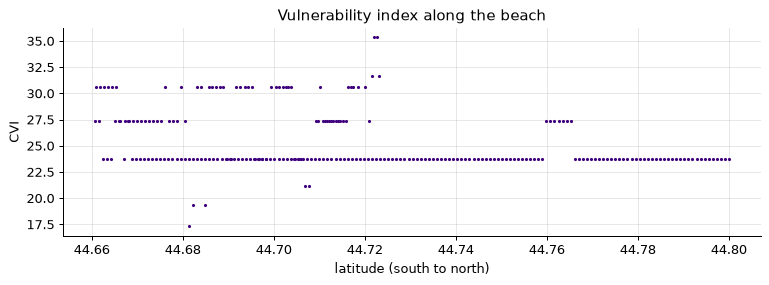

,geomorphology,shoreline_change,coastal_slope,sea_level,waves,tide
rank,,,,,,
1,0,0,0,0,0,0
2,3,0,0,0,0,0
3,11,230,148,0,0,237
4,0,5,45,0,0,0
5,223,2,44,237,237,0


In [17]:
order = vi.join(coast.set_index("transect_id")["lat"]).sort_values("lat")
ax = plt.subplots(figsize=(10, 3))[1]
ax.plot(order["lat"], order["cvi"], ".", ms=3, color="#3f007d")
ax.set(xlabel="latitude (south to north)", ylabel="CVI", title="Vulnerability index along the beach")
plt.show()
ranks = vi[[f"rank_{k}" for k in vulnerability.VARIABLES]].set_axis(vulnerability.VARIABLES, axis=1)
ranks.apply(lambda c: c.value_counts()).reindex([1, 2, 3, 4, 5]).fillna(0).astype(int).rename_axis("rank")

Its four classes, low to very high, are the quartiles of the index over every published transect
(`ceva vulnerability compute`): they compare coasts with each other, so they need the whole dataset.

## From one beach to a continent

The same steps run per unit: a 30 km tile, cut along the coast into groups of at most 300 transects, only
the sand and gravel coasts by default (`ceva batch plan`, `ceva batch run`). `ceva publish` writes the
dashboard's data, `ceva export` the dataset, `ceva frames` the image archives; the README lists the
commands.